# 01 · The data and the importance of each appraisal factor

> **Paper** &nbsp; I-Cheng Yeh and Tzu-Kuang Hsu (2018), "Building real estate
> valuation models with comparative approach through case-based reasoning",
> *Applied Soft Computing* **65**, 260-271.
> [doi:10.1016/j.asoc.2018.01.029](https://doi.org/10.1016/j.asoc.2018.01.029)
>
> **Data** &nbsp; UCI Machine Learning Repository, *Real Estate Valuation*
> ([doi:10.24432/C5J30W](https://doi.org/10.24432/C5J30W)), CC BY 4.0 — the
> Sindian circle of supply and demand, 414 transactions.

---

## What this notebook establishes

1. The file released by UCI **is** the Sindian circle of the paper: its descriptive statistics reproduce the Sindian row of Table 1 to the second decimal.
2. The **sorting quantile method** (Eq. 8) recovers the factor ranking the paper reports in Section 5.1 — distance to the nearest MRT station, then convenience stores, then house age, then transaction date.

That ranking is not a side result. It fixes the order in which the stepwise decomposition peels the factors off in notebook 02, and it sets the weights of the case distance in notebook 03.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qca import config, data, experiments, importance, metrics, plots
from qca.decomposition import StepwiseDecomposition
from qca.estimator import QuantitativeComparativeApproach
from qca.benchmarks import MultivariateRegression, PaperMLP

plots.use_paper_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Loading

`qca.data.load` does three things: it renames the UCI columns to short names, floors house age at 0.10 year, and projects latitude/longitude onto a local northing/easting grid in metres.

The flooring is worth justifying. Table 1 of the paper reports a minimum house age of 0.10 for Sindian, but the UCI release stores 17 of those transactions as exactly 0.0. The adjustment coefficient of house age is a **logarithmic** model, which is undefined at zero, so the ages are floored at the value the paper itself reports rather than at an arbitrary epsilon.

In [2]:
df = data.load()
print(f"{len(df)} transactions, {df.shape[1]} columns")
df.head()

414 transactions, 10 columns


,id,date,age,mrt,stores,lat,lon,price,northing,easting
0,1,"2,012.9167",32.0000,84.8788,10,24.9830,121.5402,37.9000,"1,551.1633",693.4106
1,2,"2,012.9167",19.5000,306.5947,9,24.9803,121.5395,42.2000,"1,257.6083",619.8249
2,3,"2,013.5833",13.3000,561.9845,5,24.9875,121.5439,47.3000,"2,049.3173","1,063.3553"
3,4,"2,013.5000",13.3000,561.9845,5,24.9875,121.5439,54.8000,"2,049.3173","1,063.3553"
4,5,"2,012.8333",5.0000,390.5684,5,24.9794,121.5425,43.1000,"1,149.7491",916.1838


In [3]:
# How many ages the UCI file stores as exactly zero.
raw = data.load_raw()
print("ages recorded as 0.0 in the raw file:", int((raw["age"] == 0).sum()))
print("minimum age after flooring:", df["age"].min())

ages recorded as 0.0 in the raw file: 17
minimum age after flooring: 0.1


## 2. Table 1 of the paper

If this matches, the dataset identification is settled.

In [4]:
table1 = data.descriptive_statistics(df)
table1

,Min,Max,Mean,Standard deviation,Number
Independent variable,,,,,
Distance to the nearest MRT station,23.3828,"6,488.0210","1,083.8857","1,262.1096",414
Number of convenience stores in the living circle on foot,0.0000,10.0000,4.0942,2.9456,414
House age,0.1000,43.8000,17.7167,11.3861,414
Transaction date,"2,012.6667","2,013.5833","2,013.1490",0.2820,414


In [5]:
paper_table1 = pd.DataFrame(
    {
        "Min": [23.38, 0.00, 0.10, 2012.67],
        "Max": [6488.02, 10.00, 43.80, 2013.58],
        "Mean": [1083.89, 4.09, 17.71, 2013.15],
        "Standard deviation": [1262.11, 2.95, 11.39, 0.28],
        "Number": [414, 414, 414, 414],
    },
    index=table1.index,
)
difference = (table1 - paper_table1).abs()
print("largest absolute difference from the printed Table 1:",
      round(float(difference.max().max()), 4))
difference

largest absolute difference from the printed Table 1: 0.0067


,Min,Max,Mean,Standard deviation,Number
Independent variable,,,,,
Distance to the nearest MRT station,0.0028,0.0010,0.0043,0.0004,0
Number of convenience stores in the living circle on foot,0.0000,0.0000,0.0042,0.0044,0
House age,0.0000,0.0000,0.0067,0.0039,0
Transaction date,0.0033,0.0033,0.0010,0.0020,0


Every cell agrees to rounding. The released file is the Sindian circle, and the replication can proceed against the published numbers rather than against a reconstruction.

## 3. The target variable

Price is in 10,000 New Taiwan dollars per *ping* (1 ping = 3.3 m²). Note the single transaction at 117.5, far above the rest — it reappears in notebook 03 as an influential comparative case.

count   414.0000
mean     37.9800
std      13.6100
min       7.6000
25%      27.7000
50%      38.4500
75%      46.6000
max     117.5000


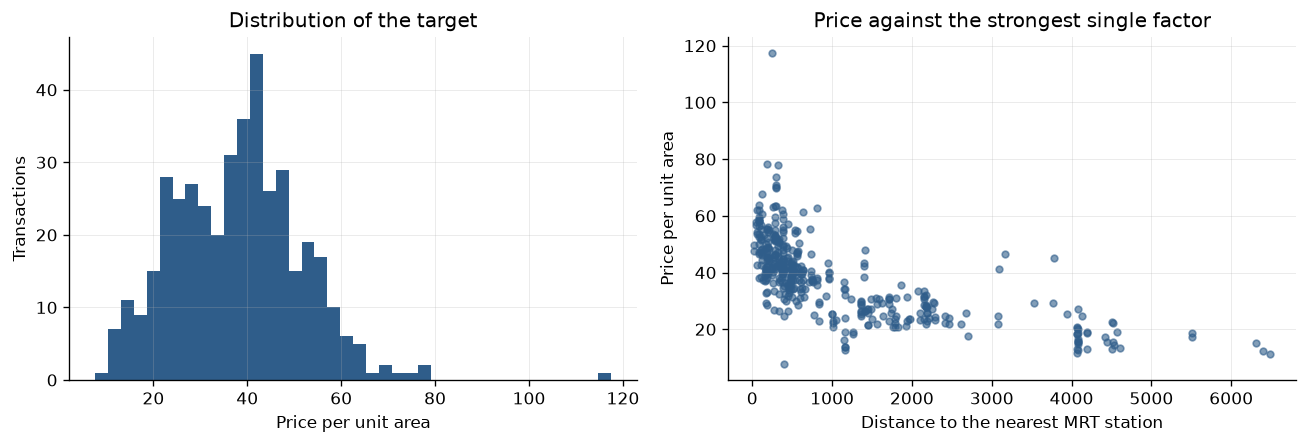

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["price"], bins=40, color=plots.PALETTE[0])
axes[0].set_xlabel("Price per unit area")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Distribution of the target")
axes[1].scatter(df["mrt"], df["price"], s=16, alpha=0.6)
axes[1].set_xlabel(config.LABELS["mrt"])
axes[1].set_ylabel("Price per unit area")
axes[1].set_title("Price against the strongest single factor")
fig.tight_layout()
print(df["price"].describe().round(2).to_string())

## 4. The sorting quantile method (Eq. 8)

The paper's measure of importance is deliberately simple and non-parametric. Sort the sample by a factor, cut it into ten equal portions, take the mean price of each portion, and sum the squared deviations of those ten means from the grand mean:

$$\mathrm{Var} = \sum_{i=1}^{10}\left(\bar{Y}_i - \bar{Y}\right)^2$$

A factor that sorts the sample into portions with very different mean prices explains a lot of price; one that does not, does not. Because it only uses the ordering of the factor it is indifferent to monotone rescaling and to the functional form of the relationship — which matters here, because half of the relationships turn out to be non-linear, the most important one most of all.

One implementation detail decides whether this works at all. The transaction date takes only 12 distinct values across 414 rows, so quantile cut points collapse: `pd.qcut` cannot produce ten portions from twelve heavily tied values. Splitting the *sort order* into ten equal blocks always can, and that is what `portion_indices` does.

In [7]:
print("distinct values per factor:")
for f in config.DECOMPOSITION_ORDER:
    print(f"  {config.LABELS[f]:<60s} {df[f].nunique():>4d}")

distinct values per factor:
  Distance to the nearest MRT station                           259
  Number of convenience stores in the living circle on foot      11
  House age                                                     236
  Transaction date                                               12


In [8]:
train, test = data.train_test_split_paper(df, config.RANDOM_STATE)
print(f"training {len(train)} / test {len(test)} (the paper's 2:1 split)")

imp = importance.factor_importance(train)
imp

training 276 / test 138 (the paper's 2:1 split)


,label,variance,root_variance,rank
factor,,,,
mrt,Distance to the nearest MRT station,"1,082.7010",32.9044,1
stores,Number of convenience stores in the living cir...,718.9754,26.8137,2
age,House age,376.6119,19.4065,3
date,Transaction date,129.3836,11.3747,4


The ranking is the paper's: **MRT distance > convenience stores > house age > transaction date**, which is finding (1) of Section 6.

The *levels* differ from the paper's Table 3 weights because the paper fits on a training split it never published, and because the transaction date — the denominator of every weight ratio — has the smallest and therefore the noisiest variance of the four. The ratios among the top three factors are nonetheless close to the published ones, which is the part that drives the case distance.

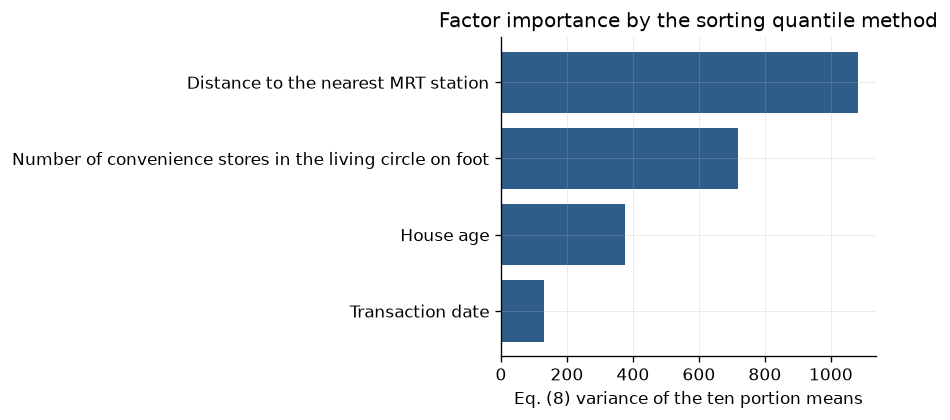

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(
    [config.LABELS[f] for f in imp.index][::-1],
    imp["variance"][::-1],
    color=plots.PALETTE[0],
)
ax.set_xlabel("Eq. (8) variance of the ten portion means")
ax.set_title("Factor importance by the sorting quantile method")
fig.tight_layout()

### Why the portion means are the whole story

Plotting the ten portion means directly shows what the statistic is picking up, and previews the shapes that notebook 02 has to fit.

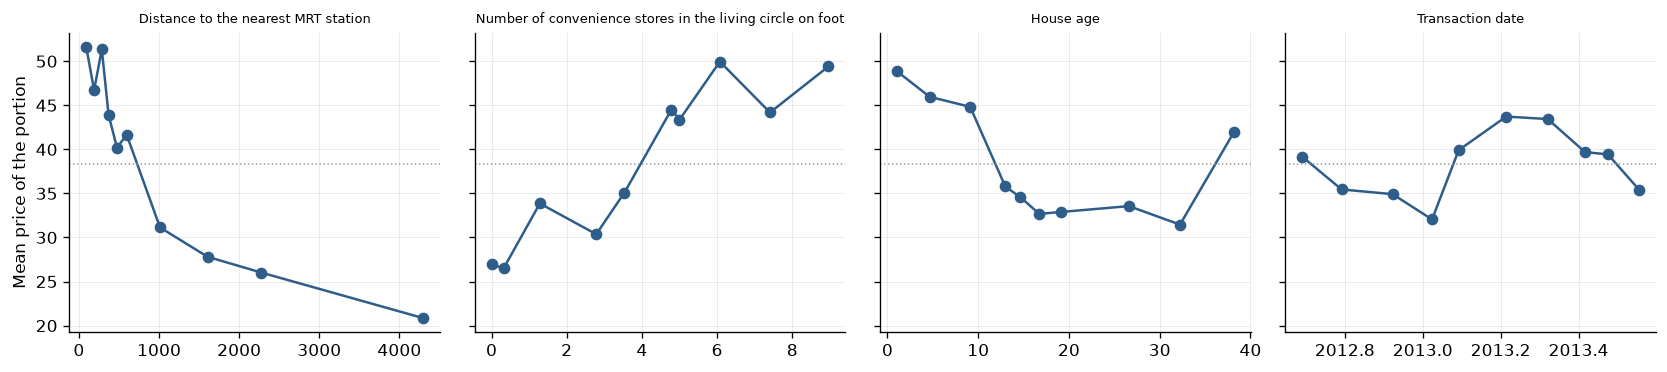

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
y = train["price"].to_numpy()
for ax, factor in zip(axes, config.DECOMPOSITION_ORDER):
    x = train[factor].to_numpy()
    idx = importance.portion_indices(x)
    ax.plot([x[i].mean() for i in idx], [y[i].mean() for i in idx],
            marker="o", color=plots.PALETTE[0])
    ax.axhline(y.mean(), color="0.6", ls=":", lw=0.9)
    ax.set_title(config.LABELS[factor], fontsize=8)
axes[0].set_ylabel("Mean price of the portion")
fig.tight_layout()

The MRT panel is a decaying curve, not a line — which is exactly why the paper fits a logarithmic adjustment coefficient to it in the next notebook.